<a href="https://colab.research.google.com/github/Gchirico63/Didattica/blob/main/AI_ExperimentalPhysics/doublependulum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

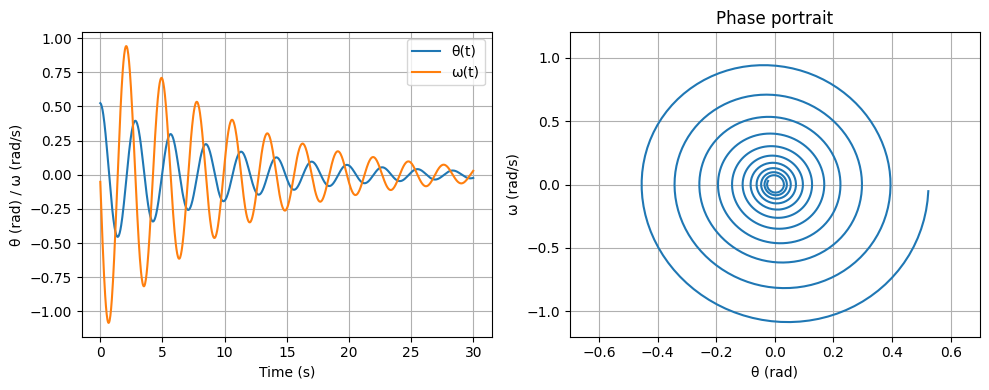

In [21]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

L = 2          # length of pendulum in m
gravity = 9.81 # m/s^2
gamma = 0.1    # damping coefficient s^-1
OMEGA = np.sqrt(gravity/L)
theta0 = np.pi/6

tempo = np.linspace(0, 30, 1000)

theta = theta0 * np.cos(OMEGA*tempo) * np.exp(-gamma*tempo)
omega = (-OMEGA*theta0 * np.sin(OMEGA*tempo)
         - gamma*theta0 * np.cos(OMEGA*tempo)) * np.exp(-gamma*tempo)

F, A = plt.subplots(1, 2, figsize=(10,4))

A[0].plot(tempo, theta, label='θ(t)')
A[0].plot(tempo, omega, label='ω(t)')
A[0].set_xlabel('Time (s)')
A[0].set_ylabel('θ (rad) / ω (rad/s)')
A[0].legend()
A[0].grid()

A[1].plot(theta, omega)
A[1].set_xlabel('θ (rad)')
A[1].set_ylabel('ω (rad/s)')
A[1].set_xlim(-0.7, 0.7)
A[1].set_ylim(-1.2, 1.2)
A[1].set_title('Phase portrait')
A[1].grid()

plt.tight_layout()
plt.show()


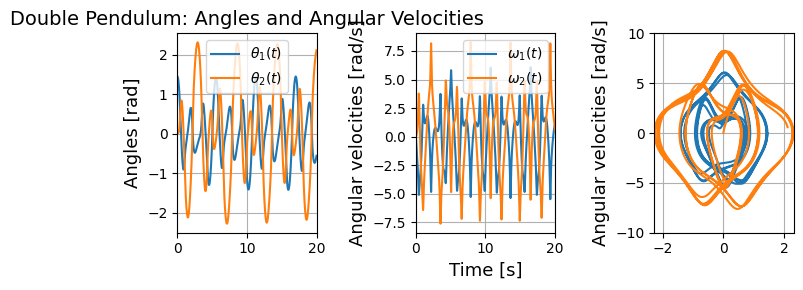

In [71]:
import numpy as np
from scipy.integrate import solve_ivp
import matplotlib.pyplot as plt

# Physical parameters
g  = 9.81     # gravityin m/s^2
L1 = 1.0      # length of first rod in m
L2 = 1.0      # length of second rod in m
m1 = 1.0      # mass 1 in kg
m2 = 1.0      # mass 2 in kg

def double_pendulum_equations(t, y):
    """
    y = [theta1, omega1, theta2, omega2]
    """
    th1, w1, th2, w2 = y

    # Useful shorthand
    dth = th2 - th1

    # Equations of motion (standard form)
    denom = (m1 + m2)*L1 - m2*L1*np.cos(dth)*np.cos(dth)

    # theta1 double dot .. acceleration
    # w1 is the omega, the first derivative of theta
    th1_dd = (m2*L1*w1*w1*np.sin(dth)*np.cos(dth)
              + m2*g*np.sin(th2)*np.cos(dth)
              + m2*L2*w2*w2*np.sin(dth)
              - (m1 + m2)*g*np.sin(th1)) / denom

    # theta2 double dot .. acceleration
    th2_dd = (-m2*L2*w2*w2*np.sin(dth)*np.cos(dth)
              + (m1 + m2)*(g*np.sin(th1)*np.cos(dth)
              - L1*w1*w1*np.sin(dth)
              - g*np.sin(th2))) / (L2*((m1 + m2)
              - m2*np.cos(dth)*np.cos(dth)))

    return [w1, th1_dd, w2, th2_dd]

# Initial conditions
theta1_0 = np.pi/6 + np.random.rand()      # 90 degrees
theta2_0 = 0      # 90 degrees
omega1_0 = 0.0
omega2_0 = 0.0

y0 = [theta1_0, omega1_0, theta2_0, omega2_0]

# Time span
tmax = 20
t_span = (0, tmax)
t_eval = np.linspace(0, tmax, 5000)

# Solve ODE
sol = solve_ivp(double_pendulum_equations, t_span, y0, t_eval=t_eval)

theta1 = sol.y[0]
omega1 = sol.y[1]
theta2 = sol.y[2]
omega2 = sol.y[3]

fig, (ax1, ax2,ax3) = plt.subplots(1, 3, figsize=(7, 3))

# --- top panel: angles ---
ax1.plot(sol.t, theta1, label=r'$\theta_1(t)$')
ax1.plot(sol.t, theta2, label=r'$\theta_2(t)$')
ax1.set_ylabel('Angles [rad]', fontsize=13)
ax1.set_xlim(0, tmax)
ax1.legend()
ax1.grid(True)
ax1.set_title('Double Pendulum: Angles and Angular Velocities', fontsize=14)

# --- bottom panel: angular velocities ---
ax2.plot(sol.t, omega1, label=r'$\omega_1(t)$')
ax2.plot(sol.t, omega2, label=r'$\omega_2(t)$')
ax2.set_ylabel('Angular velocities [rad/s]', fontsize=13)
ax2.set_xlabel('Time [s]', fontsize=13)
ax2.set_xlim(0, tmax)
ax2.legend()
ax2.grid(True)

ax3.plot(theta1, omega1, label=r'$\omega_1(t)$')
ax3.plot(theta2, omega2, label=r'$\omega_2(t)$')
ax3.set_xlim( np.minimum(theta1.min(),theta2.min()), max(theta1.max(),theta2.max()))
ax3.set_ylim(-10, 10)
ax3.grid(True)
ax3.set_ylabel('Angular velocities [rad/s]', fontsize=13)
plt.tight_layout()
plt.show()
